In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import SimpleITK as sitk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.mass_detect.scripts.config import FEATURES_FILE, LNDB_DIR, PATCHES_DIR
from src.mass_detect.scripts.features import measure_all_patches, segment_from_centre
from src.mass_detect.scripts.models import CorrelationFilter, OrdinalLogisticRegression, make_size_model, size_target
from src.mass_detect.scripts.patches import extract_patch
from src.mass_detect.scripts.radiomics_features import LOG_SIGMAS_MM, SETTINGS, extract_training_radiomics, icc_2_1
from src.mass_detect.scripts.validation import grouped_cv_predictions, summarise
from src.mass_detect.scripts.cohort import select_cohort
from src.mass_detect.scripts.config import LIDC_MANIFEST_FILE, LNDB_MANIFEST_FILE, READINGS_FILE, ROI_DIR, ROI_RADIOMICS_FILE
from src.mass_detect.scripts.rois import add_roi_diameters, build_readings, build_rois, extract_roi_radiomics, radiomic_columns, reader_icc, roi_quality
from src.mass_detect.scripts.sensitivity import (SPACINGS_MM, SPACING_DIR, acquisition_table, consensus_rows, coverage_table, cube_extents,
                                                 cube_fit_table, extract_at_spacings, feature_columns, load_spacing_features,
                                                 prediction_table, robustness_table)

# Segmentation, features and radiomics

The functions live in `src/mass_detect/note/features.py` (handcrafted features) and `src/mass_detect/note/radiomics_features.py` (PyRadiomics and ICC).

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Project code - Segmentation and Features
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Segmenting the nodule and measuring it
  </h3>
  <p>
  The input is a 64 x 64 x 64 patch with 1 mm voxels, so distances are in mm and volumes in mm3. The only thing we know about the nodule is that its centre is at voxel (32, 32, 32).
  </p>
  <p><strong>Segmentation in five steps:</strong></p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Smooth the patch lightly (sigma 0.7 mm) to reduce noise.</li>
    <li style="margin-bottom: 8px;">Threshold halfway between the HU at the centre and the HU of the surrounding lung, which adapts to solid nodules (about 0 HU) and to ground glass ones (about -500 HU).</li>
    <li style="margin-bottom: 8px;">Keep the connected region that touches the center.</li>
    <li style="margin-bottom: 8px;">Vessels and the pleura are also above the threshold and touch the nodule. We measure the widest sphere that fits inside the region near the centre (the nodule itself) and cut everything that lies further than 1.2 times that radius from it.</li>
    <li style="margin-bottom: 8px;">Keep the connected region that touches the center again.</li>
  </ol>
  <p><strong>Two safeguards were added:</strong></p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Intensities are clipped to [-1024, 3071] HU before any feature is computed. This is the range of a 12 bit CT. Values outside it are padding or artefacts (we found -8192 and 22544 in some patches) and would distort means and percentiles. The IBSI calls this step re-segmentation by intensity range (Zwanenburg et al., 2020).</li>
    <li style="margin-bottom: 8px;">Sphere features. Some findings cannot be segmented (8% of the rated training nodules), and the model then had nothing but imputed values for them. Statistics in spheres of 3, 5 and 8 mm around the centre need no mask at all, so they exist for every finding, in training and in test alike.</li>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   PyRadiomics with an IBSI oriented configuration
  </h3>
  <p>
  PyRadiomics is a library which helps calculate hundreds of features of the images inside a desired region. Configuration (IBSI: Zwanenburg et al., 2020; PyRadiomics: van Griethuysen et al., 2017):
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Isotropic 1 mm voxels with linear interpolation: already done when the patch is cut so PyRadiomics does not resample again. Texture features depend on voxel size (Shafiq-ul-Hassan et al., 2017). The IBSI asks for isotropic voxels but does not fix their size, and its own reference configurations use 2 mm; 1 mm is the slice spacing of 289 of the 294 LNDb scans. The last section of this notebook tests other sizes.</li>
    <li style="margin-bottom: 8px;">Intensity range [-1024, 3071] HU before discretisation (IBSI re-segmentation by range).</li>
    <li style="margin-bottom: 8px;">Fixed bin width of 25 HU. For calibrated units such as HU the IBSI recommends a fixed bin size, so that a bin means the same density in every scan; 25 HU is the PyRadiomics default and widely used in CT.</li>
    <li style="margin-bottom: 8px;">Feature classes: first order, shape, GLCM, GLRLM, GLSZM, GLDM and NGTDM, on the original image and on Laplacian of Gaussian filtered images with sigma 1, 2 and 3 mm (edges and blobs at the scales of small nodules). PyRadiomics documents where its definitions deviate from the IBSI.</li>
    <li style="margin-bottom: 8px;">Region of interest: the same automatic mask in training and test (nodule_features.segment_from_centre), because the test file only has centres (Pedrosa et al., 2019). The radiologists' masks are used only to measure robustness.</li>
  </ul>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   ICC - what does it measure?
  </h3>

  <p>
    Two radiologists never draw exactly the same contour, so a feature computed from each of their masks will differ a little on the same nodule. The intraclass correlation coefficient (ICC) asks whether that difference is small compared with the differences between nodules: it is the share of the total variability that comes from real differences between nodules rather than from who drew the contour. An ICC of 1 means the two radiologists give the same value for every nodule; an ICC of 0 means the disagreement between them is as large as the differences between nodules, so the feature describes the contour more than the nodule.   
  </p>
  <p>
    We use ICC(2,1) (Shrout and Fleiss, 1979): absolute agreement, so that a systematic difference (one radiologist always drawing larger contours) also lowers the score, unlike a plain correlation; random raters, because the feature should hold for any radiologist and not only for these five; and a single rater, because the model uses one mask per nodule. Following Koo and Li (2016), we call a feature robust when its ICC is at least 0.75.
  </p>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    From Patches to Features
  </h1>

  <p>
Test rows only give us the centre of each finding, nothing else. So everything the model knows about a finding has to be measured from its patch, with the same procedure for training and test. The path is:
  </p>

  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Segment the nodule that sits at the centre of the patch.</li>
    <li style="margin-bottom: 8px;">Measure it (size, shape, density, surroundings), plus statistics in spheres that need no segmentation.</li>
    <li style="margin-bottom: 8px;">Radiomics: PyRadiomics features with an IBSI oriented configuration, and how robust they are when the contour changes.</li>
  </ol>
</div>

In [3]:
pd.set_option("display.width", 140)

# Measure the patches and extract the radiomic features if this was not done yet. Functions: src/mass_detect/note/features.py and src/mass_detect/note/radiomics_features.py
if not FEATURES_FILE.exists():
    measure_all_patches()
if not (PATCHES_DIR / "radiomics_train.csv").exists():
    extract_training_radiomics()
print("features:", pd.read_csv(FEATURES_FILE).groupby("split").size().to_dict())

features: {'lidc': 2663, 'test': 2895, 'train': 1219}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Segmenting the nodule from its center
  </h3>
  <p>
  The test file gives only the centre of each finding, so the region of the nodule must be found automatically, and in exactly the same way in training and in test. The method therefore has to be simple, deterministic and robust to the two kinds of nodule we meet: solid ones, about as dense as soft tissue, and ground glass ones, a hazy increase in density through which vessels remain visible Our process works in 5 steps.
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Light smoothing (Gaussian, sigma 0.7 mm). CT images contain noise, so a few voxels inside a nodule fall below any threshold and a few voxels of lung rise above it. Thresholding a noisy image gives a ragged mask with holes and isolated specks. A light Gaussian filter is the standard remedy before thresholding (Gonzalez and Woods, 2018). We keep sigma below one voxel (0.7 mm) so that the edges of nodules of 3 to 5 mm are not blurred away.</li>
    <li style="margin-bottom: 8px;">An adaptive threshold halfway between the nodule and the lung. We measure the density of the centre (median within 2 mm) and of the surrounding lung (median of the voxels below −500 HU in a shell 24 to 31 mm from the centre; −850 HU if there are too few), and threshold halfway between the two, never above −300 HU. Because of the partial volume effect, voxels on the border of a nodule mix nodule and lung, so the true edge lies where the intensity is halfway between object and background, the same idea as the full width at half maximum. A fixed threshold cannot serve both kinds of nodule: −400 HU captures a solid nodule (centre about 0 HU, threshold −425 HU with ours) but misses a ground glass one entirely (centre about −500 HU, threshold −675 HU with ours). The cap at −300 HU protects calcified nodules: with a centre at +400 HU a halfway threshold would cut away their softer parts. If the centre is not at least 150 HU denser than the lung, there is no nodule-like structure and the mask is left empty.</li>
    <li style="margin-bottom: 8px;">Keep the region connected to the centre. Many structures in the patch exceed the threshold: other vessels, ribs, the heart. Only the object the finding points at matters, so we keep the connected component that touches the centre (connected component labelling; Gonzalez and Woods, 2018), within 28 mm of it.</li>
    <li style="margin-bottom: 8px;">Cut the attachments to vessels and pleura. Vessels and the chest wall are as dense as the nodule and often touch it, so the region of step 3 may include a long piece of vessel or a slice of pleura, and its volume would be far too large. Separating a nodule from attached structures is the main difficulty of nodule segmentation. Published methods use morphological opening (Kostis et al., 2003) or combine region growing, morphology and a partial volume analysis (Kuhnigk et al., 2006). We use a simpler geometric rule. The Euclidean distance transform gives, for every voxel of the region, its distance to the region's border (Danielsson, 1980). The deepest voxel near the centre (within 1.5 mm) is the centre of the largest sphere that fits inside the region, and its distance is that sphere's radius r. A vessel is a thin tube, so the spheres that fit inside it are small; the largest one sits in the nodule, which is the thickest part. We then remove every voxel farther than 1.2 × r + 1 mm from that point. The 20% margin and the extra millimetre keep the irregular border of the nodule (lobulation, short spicules), while vessels leaving the nodule and the pleural surface are cut off.</li>
    <li style="margin-bottom: 8px;">Keep the region connected to the centre again. The cut of step 4 can leave loose pieces, for example the end of a vessel that lies within the radius but no longer touches the nodule. We keep only the component that contains the centre of the inscribed sphere.</li>
  </ol>

<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Checking against the radiologists' masks
  </h3>
    <p>
    LNDb has a hand drawn mask for most nodules of 3 mm or more. For a random sample of 250 of them, we compare our mask with each radiologist's mask using the Dice coefficient (1 means identical, 0 means no overlap), and our equivalent diameter with theirs. As a reference for how hard this is, we also measure the Dice between two radiologists on the same nodule.
    </p>
</div>

In [4]:
table = pd.read_csv("nodule_table.csv")
lndb = table[table.dataset == "LNDb"].copy()
gt = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainNodules_gt.csv")
gt["nodule_uid"] = gt.apply(lambda r: f"LNDb-{r.LNDbID:04d}_{r.FindingID}", axis=1)
has_mask = lndb[lndb.mal_mean.notna() & ~lndb.volume_is_placeholder]
gt = gt.merge(has_mask[["nodule_uid"]], on="nodule_uid")
sample = gt.iloc[np.random.default_rng(1).choice(len(gt), size=250, replace=False)].sort_values("LNDbID")

def diameter(voxels):
    return 2 * (3 * voxels / (4 * np.pi)) ** (1 / 3)

records = []
for r in sample.itertuples():
    patch = np.load(PATCHES_DIR / f"train/LNDb-{r.LNDbID:04d}_f{r.FindingID:03d}.npy")
    references = []
    for rad, finding in zip(str(r.RadID).split(","), str(r.RadFindingID).split(",")):
        mask_file = LNDB_DIR / "LNDb_masks" / "masks" / f"LNDb-{r.LNDbID:04d}_rad{rad}.mhd"
        mask_patch, _ = extract_patch(sitk.ReadImage(str(mask_file)), (r.x, r.y, r.z),
                                      interpolator=sitk.sitkNearestNeighbor, outside_value=0)
        references.append(mask_patch == int(finding))
    mask, _ = segment_from_centre(patch)
    dice = lambda a, b: 2 * (a & b).sum() / max(a.sum() + b.sum(), 1)
    records.append({"uid": r.nodule_uid, "patch": patch, "mask": mask, "refs": references,
                    "dice": np.mean([dice(mask, q) for q in references]),
                    "diameter": diameter(mask.sum()), "ref_diameter": diameter(np.mean([q.sum() for q in references])),
                    "reader_dice": dice(references[0], references[1]) if len(references) > 1 else np.nan})
check = pd.DataFrame(records)
half = len(check) // 2
rows = {}
for name, part in (("first half (used to pick parameters)", check.iloc[:half]), ("second half (not used)", check.iloc[half:]), ("all 250", check)):
    rows[name] = {"median Dice": part.dice.median(), "mean Dice": part.dice.mean(),
                  "diameter correlation": part.diameter.corr(part.ref_diameter),
                  "mean abs diameter error (mm)": (part.diameter - part.ref_diameter).abs().mean(),
                  "mean diameter bias (mm)": (part.diameter - part.ref_diameter).mean()}
print(pd.DataFrame(rows).T.round(2).to_string())
print(f"\nDice between two radiologists on the same nodule: median {check.reader_dice.median():.2f}, mean {check.reader_dice.mean():.2f} (n={check.reader_dice.notna().sum()})")
print(f"nodules the pipeline could not segment: {(check['mask'].apply(lambda m: m.sum()) == 0).sum()} of 250")

                                      median Dice  mean Dice  diameter correlation  mean abs diameter error (mm)  mean diameter bias (mm)
first half (used to pick parameters)         0.64       0.60                  0.74                          1.38                    -0.01
second half (not used)                       0.59       0.55                  0.67                          1.56                    -0.20
all 250                                      0.64       0.57                  0.72                          1.47                    -0.10

Dice between two radiologists on the same nodule: median 0.74, mean 0.68 (n=90)
nodules the pipeline could not segment: 13 of 250


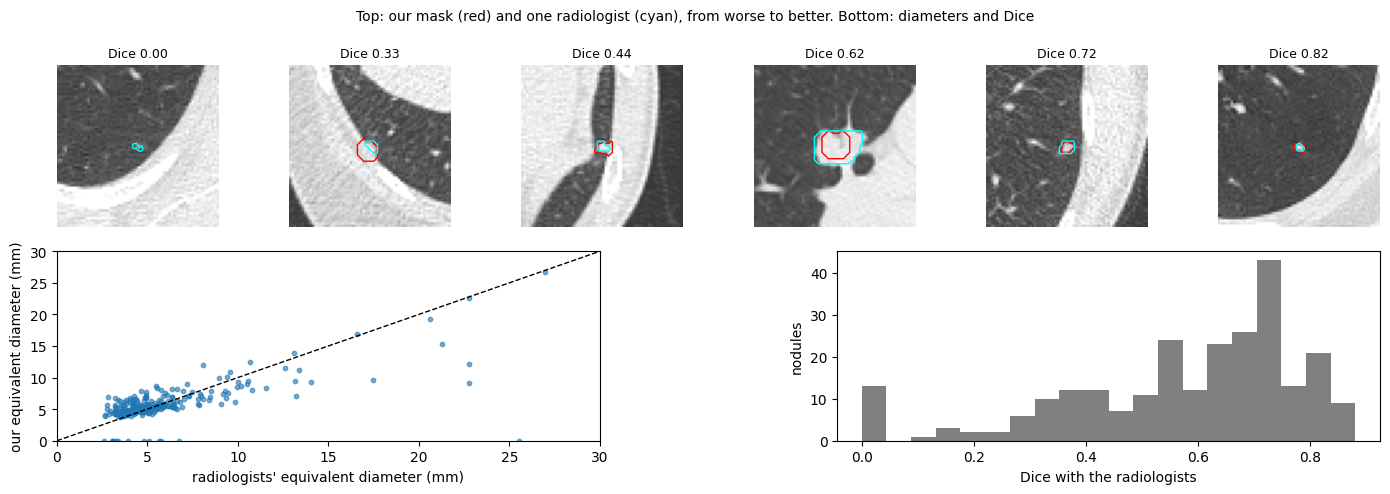

In [5]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
order = check.sort_values("dice")
picks = list(order.iloc[[10, 30, 60]].index) + list(order.iloc[[120, 180, 235]].index)
for axis, i in zip(axes[0], picks):
    p, m, q = check.patch[i], check["mask"][i], check.refs[i][0]
    axis.imshow(p[32], cmap="gray", vmin=-1350, vmax=150)
    axis.contour(m[32], levels=[.5], colors="red", linewidths=1)
    axis.contour(q[32], levels=[.5], colors="cyan", linewidths=1)
    axis.set_title(f"Dice {check.dice[i]:.2f}", fontsize=9); axis.axis("off")
axes[0, 0].set_ylabel("axial")
a = axes[1, 0]; a.remove()
ax = fig.add_subplot(2, 2, 3)
ax.scatter(check.ref_diameter, check.diameter, s=10, alpha=.6); ax.plot([0, 30], [0, 30], "k--", lw=1)
ax.set_xlabel("radiologists' equivalent diameter (mm)"); ax.set_ylabel("our equivalent diameter (mm)"); ax.set_xlim(0, 30); ax.set_ylim(0, 30)
for a in axes[1, 1:]: a.remove()
ax2 = fig.add_subplot(2, 2, 4)
ax2.hist(check.dice, bins=20, color="grey"); ax2.set_xlabel("Dice with the radiologists"); ax2.set_ylabel("nodules")
fig.suptitle("Top: our mask (red) and one radiologist (cyan), from worse to better. Bottom: diameters and Dice", fontsize=10)
plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
The two radiologists agree with each other much better than we agree with them, so our segmentation is not at their level. It is good enough to measure size on average (small bias, error around 1.5 mm) and fails mostly on nodules attached to vessels or the chest wall. We keep it because it uses nothing but the centre, so it can be applied to the test rows. A better segmentation is the most direct way to improve the features later.
</p>
<p>
One more check: the cube is 64 mm. Does any rated nodule risk being cut?
</p>
</div>

In [6]:
rated = lndb[lndb.mal_mean.notna()]
print("rated LNDb nodules:", len(rated))
print("with a radiologist diameter above 40 mm:", int((rated.diameter_mm > 40).sum()), "| above 30 mm:", int((rated.diameter_mm > 30).sum()))

rated LNDb nodules: 765
with a radiologist diameter above 40 mm: 0 | above 30 mm: 2


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    What we measure
  </h3>
<p>
For every patch we compute 21 numbers on the segmented nodule and 9 numbers in spheres around the centre. We wrote them ourselves instead of starting from the hundreds of PyRadiomics features, for three reasons: with 765 labelled nodules, hundreds of features invite overfitting; each of ours has a plain meaning that we can explain; and they are fast. Section 4 checks whether PyRadiomics adds anything.
</p>

| Group | Features | Why |
|---|---|---|
| Size | 'volume_mm3', 'diameter_mm' (of the sphere with the same volume), 'max_extent_mm' | Size is the first thing a radiologist looks at, and a diameter only baseline is strong in LIDC (Baltatzis et al., 2021) |
| Shape | 'elongation', 'flatness', 'sphericity' | Round and smooth nodules look different from spiculated or elongated ones |
| Density inside | 'hu_mean', 'hu_std', 'hu_p10', 'hu_p50', 'hu_p90', 'hu_skew' | Calcified nodules are very dense and are usually benign |
| Solid or ground glass | 'solid_fraction', 'ground_glass_fraction' | Part solid and ground glass nodules are read differently from solid ones |
| Edge | 'edge_gradient' | How sharp the border is |
| Surroundings | 'ring_mean_hu', 'ring_solid_fraction', 'contrast_hu' | A dense ring means the nodule touches a vessel or the wall |
| Segmentation | 'centre_hu', 'lung_hu', 'threshold_hu' | What the segmentation measured, which also says how confident it is |
| Spheres of 3, 5 and 8 mm | mean HU, 90th percentile, solid fraction | They need no mask, so they exist even when the segmentation fails (8% of the rated nodules), in training and test alike |

<p>
Two safeguards: every intensity feature uses the patch clipped to [-1024, 3071] HU, the range of a 12 bit CT, because some patches contain padding values down to -8192 or artefacts up to 22544 HU (the IBSI calls this re-segmentation by intensity range; Zwanenburg et al., 2020). And nodules where nothing denser than the lung is found at the centre get empty segmentation features; the model fills them with the median, but their sphere features remain.
</p>
</div>

765 rated nodules; segmented: 91.9% | features: 30
test rows with features: 2895 | segmented: 98.5%
rating
1    213
2    254
3    209
4     71
5     18


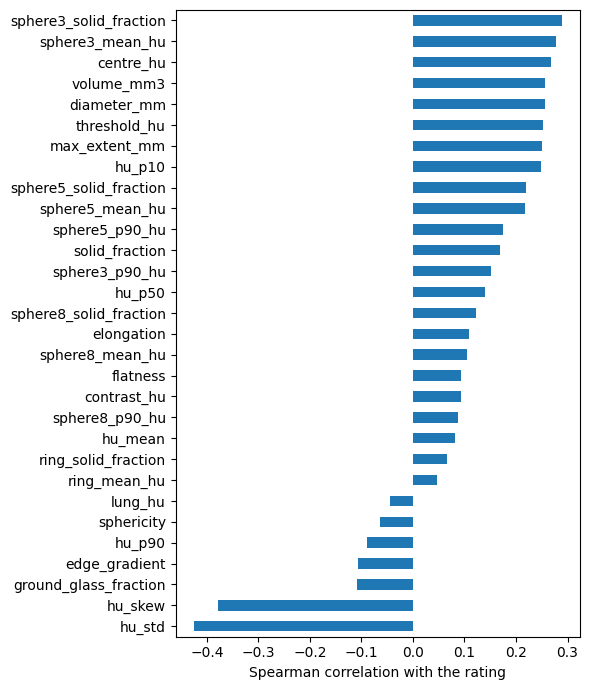

In [7]:
features = pd.read_csv(PATCHES_DIR / "features.csv")
lndb["patch_id"] = lndb.nodule_uid.str.replace(r"_(\d+)$", lambda m: f"_f{int(m.group(1)):03d}", regex=True)
data = (lndb[lndb.mal_mean.notna()].rename(columns={"diameter_mm": "diameter_mm_radiologist"}).drop(columns="volume_mm3")
        .merge(features[features.split == "train"].drop(columns="split"), on="patch_id"))
data["rating"] = np.floor(data.mal_mean + 0.5).astype(int)          # mean of the readers, rounded half up
feature_names = [c for c in features.columns if c not in ("patch_id", "split", "segmented", "error")]
print(len(data), "rated nodules; segmented:", f"{data.segmented.mean():.1%}", "| features:", len(feature_names))
print("test rows with features:", int((features.split == "test").sum()), "| segmented:", f"{features[features.split == 'test'].segmented.mean():.1%}")
print(data.rating.value_counts().sort_index().rename("nodules per class").to_string())

corr = data[feature_names + ["rating"]].corr(method="spearman")["rating"].drop("rating").sort_values()
corr.plot.barh(figsize=(6, 7)); plt.xlabel("Spearman correlation with the rating"); plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
    The strongest single signals are the density inside the nodule and in the small spheres (calcified nodules are dense and benign, so the sign is negative), the surroundings and the size. We know understand that no single feature is strong, so the combination matters.
</p>

| Step | Our choice | Why |
|---|---|---|
| Resampling | 1 mm isotropic, linear interpolation, done when the patch is cut | Texture depends on voxel size (Shafiq-ul-Hassan et al., 2017); the IBSI recommends isotropic voxels |
| Intensity range | [-1024, 3071] HU | Removes padding and artefacts before discretisation |
| Discretisation | fixed bin width of 25 HU | For calibrated units such as HU the IBSI recommends a fixed bin size, so that one bin is the same density in every scan |
| Filters | original image and Laplacian of Gaussian with sigma 1, 2 and 3 mm | Edges and blobs at the scale of small nodules |
| Feature classes | first order, shape, GLCM, GLRLM, GLSZM, GLDM, NGTDM | All classes of PyRadiomics, 386 features |
| Region | the automatic mask, identical in training and test | The test file only has centres (Pedrosa et al., 2019) |

</div>

In [8]:
print("settings:", SETTINGS, "| LoG sigmas (mm):", LOG_SIGMAS_MM)
radiomics = pd.read_csv(PATCHES_DIR / "radiomics_train.csv")
icc = pd.read_csv(PATCHES_DIR / "radiomics_icc.csv")
print("regions:", radiomics.roi.value_counts().to_dict())

settings: {'binWidth': 25, 'resampledPixelSpacing': None, 'interpolator': 'sitkLinear', 'label': 1, 'minimumROIDimensions': 1, 'minimumROISize': 8, 'geometryTolerance': 0.001} | LoG sigmas (mm): [1.0, 2.0, 3.0]
regions: {'auto': 765, 'rad1': 518, 'rad2': 393, 'rad3': 119}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Are the features robust to who draws the contour?
  </h3>
<p>
A feature that changes a lot when another radiologist draws the contour measures the contour more than the nodule (Traverso et al., 2018; Zwanenburg et al., 2019). For every nodule with masks from two radiologists we compute, feature by feature, the intraclass correlation ICC(2,1): two way random effects, absolute agreement, single rater (Shrout and Fleiss, 1979). Following Koo and Li (2016), ICC of 0.75 or more is "good" and we call the feature robust.
</p>
</div>

In [9]:
summary = icc.groupby(["image", "feature_class"]).agg(features=("icc", "size"), median_icc=("icc", "median"),
                                                      robust_share=("robust", "mean")).round(2)
print(f"{icc.robust.sum()} of {len(icc)} features are robust (ICC >= 0.75); median ICC {icc.icc.median():.2f}")
summary.unstack("image")["robust_share"]

330 of 386 features are robust (ICC >= 0.75); median ICC 0.94


image,log-sigma-1-0-mm-3D,log-sigma-2-0-mm-3D,log-sigma-3-0-mm-3D,original
feature_class,,,,
firstorder,0.83,0.89,0.94,0.67
glcm,0.88,0.92,0.96,0.75
gldm,0.86,0.93,0.93,0.79
glrlm,0.88,1.00,1.00,0.75
glszm,0.94,0.81,0.75,0.81
ngtdm,0.60,0.80,0.60,0.80
shape,NaN,NaN,NaN,0.86


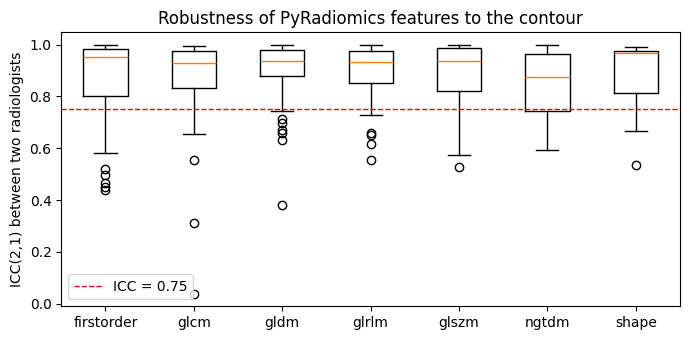

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
classes = sorted(icc.feature_class.unique())
ax.boxplot([icc.loc[icc.feature_class == c, "icc"].clip(lower=-0.2) for c in classes], tick_labels=classes)
ax.axhline(0.75, color="red", linestyle="--", linewidth=1, label="ICC = 0.75")
ax.set(ylabel="ICC(2,1) between two radiologists", title="Robustness of PyRadiomics features to the contour")
ax.legend(); plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
Most features are robust to the difference between two radiologists' contours; NGTDM and the unfiltered texture features are the least robust. But the region we can use at test time is our automatic mask, not a radiologist's. The relevant question is therefore how well features from our mask agree with features from a radiologist's mask.
</p>
</div>

In [11]:
first_reader = (radiomics[radiomics.roi.str.startswith("rad")].dropna(subset=["original_firstorder_Mean"])
                .sort_values("roi").groupby("patch_id").head(1).set_index("patch_id"))
automatic = radiomics[radiomics.roi == "auto"].dropna(subset=["original_firstorder_Mean"]).set_index("patch_id")
common = automatic.index.intersection(first_reader.index)
icc_auto = pd.Series({f: icc_2_1(np.column_stack([automatic.loc[common, f], first_reader.loc[common, f]]))
                      for f in icc.feature})
print(f"automatic mask vs radiologist ({len(common)} nodules): median ICC {icc_auto.median():.2f}, "
      f"robust {(icc_auto >= 0.75).mean():.0%} of the features")

automatic mask vs radiologist (632 nodules): median ICC 0.73, robust 47% of the features


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Between two radiologists the median ICC is about 0.94; between our mask and a radiologist it drops to about 0.73, with fewer than half of the features robust. The weak point is our segmentation, not the features.
  </p>


  
<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Do radiomics add anything to our features?
  </h3>
<p>
We compare, with the ordinal model and the same grouped cross validation, our 30 features alone against our features plus the robust radiomic features. With 300 extra features we remove redundant ones (absolute Spearman correlation above 0.9) and keep the 30 most related to the rating, both inside each training fold  and use a stronger penalty.
</p>
</div>

In [12]:
robust = ["R_" + f for f in icc.loc[icc.robust, "feature"]]
data = data.merge(automatic[icc.feature].add_prefix("R_"), left_on="patch_id", right_index=True, how="left")
own = feature_names                     # our 21 + 9 sphere features
y, groups = data.rating.to_numpy(), data.scan_id.to_numpy()

def ordinal_pipeline(selection=(), alpha=1.0):
    return lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), *[s() for s in selection],
                                 OrdinalLogisticRegression(alpha))
comparison = {
    "our 30 features": summarise(y, groups, grouped_cv_predictions(ordinal_pipeline(), data[own], y, groups, repeats=3))["mean"],
    "our features + robust radiomics": summarise(y, groups, grouped_cv_predictions(
        ordinal_pipeline((lambda: CorrelationFilter(0.9), lambda: SelectKBest(f_regression, k=30)), alpha=10.0),
        data[own + robust], y, groups, repeats=3))["mean"]}
pd.DataFrame(comparison).T

,balanced_accuracy,macro_f1,qwk,mae,composite
our 30 features,0.377,0.406,0.501,0.633,0.651
our features + robust radiomics,0.355,0.379,0.470,0.644,0.561


In [13]:
# The same question for the size model of notebook 06_modelo: does it predict the radiologists' diameter better with radiomics?
target = size_target(data.diameter_mm_radiologist).to_numpy()
measured = data.diameter_mm_radiologist.notna().to_numpy()
for name, columns in (("our features", own), ("our features + robust radiomics", own + robust)):
    predicted = np.zeros(len(data))
    for train, test in GroupKFold(5).split(data, y, groups):
        predicted[test] = make_size_model().fit(data[columns].iloc[train], target[train]).predict(data[columns].iloc[test])
    rho = pd.Series(predicted[measured]).corr(data.diameter_mm_radiologist[measured].reset_index(drop=True), method="spearman")
    print(f"size model with {name}: Spearman {rho:.3f}")

size model with our features: Spearman 0.828
size model with our features + robust radiomics: Spearman 0.822


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The robust radiomic features do not improve the model, neither as direct inputs nor through the size model, so the final model uses our 30 features. This follows the principle of keeping the simplest model that performs as well, and it agrees with the Radiomics Quality Score, which rewards feature reduction and robustness analysis rather than the number of features (Lambin et al., 2017). The radiomic analysis stays in the report as evidence. We consider that A better segmentation would be the way to make radiomics worthwhile.
  </p>


  
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Radiomics on the Radiologists' Regions
  </h1>
  <p>
  From here on the model learns from LNDb and LIDC IDRI together, and its features describe the region that the radiologists drew around each nodule. Every nodule in training and validation comes with that region, so we measure the nodule where the experts saw it, instead of where our automatic segmentation guesses it is.
  </p>
  <p>
  Three reasons led to this choice:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The same code measures both datasets. LNDb and LIDC record the size of a nodule with different tools, so their own numbers are not directly comparable. Computing everything ourselves from the masks gives one definition for all nodules.</li>
    <li style="margin-bottom: 8px;">The region is where radiomics makes sense. The IBSI defines its features inside a region of interest (Zwanenburg et al., 2020), and the features computed on two radiologists' regions agree much better with each other than with our automatic mask (section above).</li>
    <li style="margin-bottom: 8px;">The diameter, the single most important sign for the radiologist (MacMahon et al., 2017), comes out of the same region and is measured the same way in both datasets.</li>
  </ul>
  <p>
  This part builds the cohort, collects every reading, cuts the masks on the grid of the patches, extracts the PyRadiomics features and checks which features stay stable when another radiologist draws the contour. The functions live in <strong>src/mass_detect/note/cohort.py</strong> and <strong>src/mass_detect/note/rois.py</strong>.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Which nodules enter the study
  </h3>
  <p>
  A nodule enters the study only if it passes every one of these rules, applied in this order:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>It is a nodule.</strong> Non nodules carry no malignancy rating and are not what the model is asked about, so they are left out.</li>
    <li style="margin-bottom: 8px;"><strong>It has a malignancy rating.</strong> A rating of 0 in LNDb means that the field was not filled in.</li>
    <li style="margin-bottom: 8px;"><strong>It has a radiologist mask, which means it measures 3 mm or more.</strong> LIDC IDRI only describes nodules of 3 mm or more (Armato et al., 2011), while in LNDb the nodules under 3 mm were only marked with a centre (Pedrosa et al., 2019). Using the same rule in both datasets keeps the two populations comparable. Nodules this small are also of low clinical concern and do not need routine follow up (MacMahon et al., 2017).</li>
    <li style="margin-bottom: 8px;"><strong>Its LIDC group has at most four annotations.</strong> LIDC has four radiologists, so a group with more annotations mixes more than one nodule and its consensus region would not describe a single lesion.</li>
    <li style="margin-bottom: 8px;"><strong>Its LIDC position was confirmed when the patch was cut.</strong> Notebook 04 computes the centre in two independent ways and keeps the nodules where both agree within 1 mm. Without that check the mask could fall next to the nodule instead of on it.</li>
  </ol>
  <p>
  The label is the mean of the radiologists' ratings rounded half up, so 2.5 becomes 3. We study two scales: the original 1 to 5 and a 1 to 3 scale (benign for ratings 1 and 2, indeterminate for 3, suspicious for 4 and 5), which follows the decisions a clinician takes about a nodule.
  </p>
</div>

In [ ]:
# Inclusion rules and labels: src/mass_detect/note/cohort.py
cohort, funnel = select_cohort()
print(f"{len(cohort)} nodules from {cohort.patient_id.nunique()} patients")
funnel

In [ ]:
# Nodules per class, on both scales
labels = pd.concat({"1 to 5": cohort.groupby("dataset").rating.value_counts().unstack(),
                    "1 to 3": cohort.groupby("dataset").rating_3.value_counts().unstack()}, axis=1)
labels.loc["total"] = labels.sum()
labels

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The rules leave 3237 nodules from 1062 patients: 622 from LNDb and 2615 from LIDC IDRI. Most of what is lost are the 143 LNDb nodules under 3 mm, which have no mask. In LIDC IDRI, 6 groups had more than four annotations and 42 nodules could not have their position confirmed.
  </p>
  <p>
  Putting the two datasets together brings the most suspicious class from 18 nodules in LNDb alone to 120, which makes it learnable. The two datasets still rate differently: 47% of the LIDC IDRI nodules are rated 3, against 32% in LNDb. This difference in labelling habits is something the models have to deal with, and it is the reason why the next notebook compares several ways of combining the datasets.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   One row per reading
  </h3>
  <p>
  A reading is one radiologist's view of one nodule: the contour that radiologist drew and the rating that radiologist gave. We keep every reading, because the next notebook compares two ways of training: on the mean rating of each nodule, and on each reading separately. Learning from every annotator instead of only from their average is a known way to use labels from several experts who disagree (Raykar et al., 2010).
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">In LNDb each reader has one mask file per CT, in which every finding is drawn with its own number. The merged file of the dataset tells which reader and which number belong to each nodule.</li>
    <li style="margin-bottom: 8px;">In LIDC IDRI each pylidc annotation is one reading. The dataset does not say which of the four radiologists drew it, so the annotation number stands for the reader.</li>
  </ul>
</div>

In [ ]:
# One row per reading (src/mass_detect/note/rois.py); built once, then read from disk
readings = pd.read_csv(READINGS_FILE) if READINGS_FILE.exists() else build_readings(cohort)
per_nodule = readings.groupby(["dataset", "nodule_uid"]).size().rename("readers")
summary = pd.DataFrame({"readings": readings.groupby("dataset").size(),
                        "nodules": readings.groupby("dataset").nodule_uid.nunique(),
                        "mean readers per nodule": per_nodule.groupby("dataset").mean().round(2)})
summary.join(per_nodule.groupby("dataset").value_counts().unstack().add_prefix("nodules with readers = "))

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The masks, on the grid of the patch
  </h3>
  <p>
  Every mask is cut exactly like its CT patch: a cube of 64 mm with 1 mm voxels around the same centre, so that mask and patch overlap voxel by voxel. Masks use nearest neighbour interpolation, which keeps them made of whole voxels instead of blurring their border.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">LNDb: the region of a reader is the set of voxels that carry that finding's number in the reader's mask file.</li>
    <li style="margin-bottom: 8px;">LIDC IDRI: pylidc turns the contours of an annotation into a mask inside its bounding box, and we place that box in the CT with the geometry that SimpleITK reads from the DICOM files, the same geometry used to cut the patches.</li>
    <li style="margin-bottom: 8px;">Consensus: a voxel belongs to the consensus region when at least half of the readers drew it, the definition used by pylidc. With one reader the consensus is that reader's mask, and with two readers it is their union.</li>
  </ul>
  <p>
  Two checks follow. If a mask was placed in the wrong spot, its centre of mass would be far from the centre of the patch, and if a contour was lost the mask would be empty.
  </p>
</div>

In [ ]:
# Masks of every reading and the consensus, one file per nodule (src/mass_detect/note/rois.py)
if len(list(ROI_DIR.glob("*.npz"))) < len(cohort):
    build_rois(cohort, readings)
quality = roi_quality(cohort)
quality.groupby("dataset").agg(
    nodules=("patch_id", "size"),
    empty_reader_masks=("empty_reader_masks", "sum"),
    smallest_consensus_voxels=("consensus_voxels", "min"),
    median_consensus_voxels=("consensus_voxels", "median"),
    median_offset_mm=("centre_offset_mm", "median"),
    p99_offset_mm=("centre_offset_mm", lambda d: d.quantile(0.99)),
    max_offset_mm=("centre_offset_mm", "max"),
).round(2)

In [ ]:
# Six random nodules per dataset: central axial slice, consensus in red and each reader in cyan
rng = np.random.default_rng(0)
manifest = pd.concat([pd.read_csv(LNDB_MANIFEST_FILE), pd.read_csv(LIDC_MANIFEST_FILE)])
file_of = dict(zip(manifest.patch_id, manifest.file))
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for row_axes, (dataset, group) in zip(axes, cohort.groupby("dataset")):
    for axis, patch_id in zip(row_axes, rng.choice(group.patch_id, 6, replace=False)):
        patch, rois = np.load(PATCHES_DIR / file_of[patch_id]), np.load(ROI_DIR / f"{patch_id}.npz")
        axis.imshow(patch[32], cmap="gray", vmin=-1350, vmax=150)          # lung window
        for mask in rois["masks"]:
            axis.contour(mask[32], levels=[0.5], colors="cyan", linewidths=0.7)
        axis.contour(rois["consensus"][32], levels=[0.5], colors="red", linewidths=1.2)
        readers = len(rois["readers"])
        axis.set_title(f"{dataset}, {readers} reader{'s' if readers > 1 else ''}", fontsize=9)
        axis.axis("off")
plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Every mask landed where it should. The centre of the consensus region lies at a median of 0.34 mm from the centre of the patch in LIDC IDRI and 0.39 mm in LNDb, and 99% of the nodules are within 1.6 mm. The few nodules a little further away (at most 4.2 mm) are LIDC nodules of 8 to 23 mm, whose irregular shape moves their centre of mass slightly away from the marked centre.
  </p>
  <p>
  Only 2 of the 7585 reader masks came out empty: one LIDC annotation drawn on a single slice and one LNDb reader file that does not contain that finding. Both nodules keep their consensus region from the other reader, and these two readings simply have no features.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   PyRadiomics on every region
  </h3>
  <p>
  We use the same IBSI oriented configuration described above: 1 mm isotropic voxels, intensities limited to [-1024, 3071] HU, a fixed bin width of 25 HU, and every feature class on the original image and on Laplacian of Gaussian images with sigma 1, 2 and 3 mm. Features are extracted from the consensus region of every nodule, which describes the nodule, and from every reader's region, which is needed to measure robustness and to train on single readings.
  </p>
  <p>
  The diameter comes from the shape features of the same region. We keep two versions: the diameter of the sphere with the same volume as the region, and the longest diameter in an axial slice, which is how the Fleischner Society recommends measuring nodules on CT (Bankier et al., 2017). Regions smaller than 8 voxels are too small for texture and get no features.
  </p>
</div>

In [ ]:
# PyRadiomics on every region (about 10 minutes with 12 processes), then read from disk
features = pd.read_csv(ROI_RADIOMICS_FILE) if ROI_RADIOMICS_FILE.exists() else extract_roi_radiomics(cohort)
features = add_roi_diameters(features)
names = radiomic_columns(features)
consensus = features[features.roi == "consensus"].merge(cohort[["patch_id", "dataset", "diameter_mm", "rating"]], on="patch_id")
print(f"{len(features)} regions ({len(consensus)} consensus and {len(features) - len(consensus)} reader regions), "
      f"{len(names)} PyRadiomics features each")
print("regions without features (8 voxels or fewer):", features.groupby(features.roi == "consensus")[names[0]].apply(lambda c: c.isna().sum())
      .rename({True: "consensus", False: "readers"}).to_dict())

In [ ]:
# Two quick checks on the diameter of the consensus region, per dataset (Spearman correlation)
pd.DataFrame({dataset: {"with the diameter recorded by the dataset": g[["roi_diameter_mm", "diameter_mm"]].corr("spearman").iloc[0, 1],
                        "with the rating": g[["roi_diameter_mm", "rating"]].corr("spearman").iloc[0, 1],
                        "median diameter (mm)": g.roi_diameter_mm.median(),
                        "median axial diameter (mm)": g.roi_axial_diameter_mm.median()}
              for dataset, g in consensus.groupby("dataset")}).round(3)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The diameter of the consensus region agrees almost perfectly with the one recorded by each dataset (Spearman 0.98 in both), which confirms that masks and patches are aligned. Its relation with the rating is moderate (0.47 in LIDC IDRI and 0.39 in LNDb): size matters a lot, but it does not explain the rating on its own, which is why intensity and texture features are needed as well. The axial diameter is larger than the equivalent one (median 7.2 against 5.6 mm in LIDC IDRI), as expected, because the longest axis of a nodule is longer than the diameter of a sphere with the same volume.
  </p>
  <p>
  13 consensus regions and 46 reader regions have 8 voxels or fewer, below the minimum PyRadiomics accepts, so they have no features. They are all tiny nodules and are handled later as missing values.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Which features stay stable when another radiologist draws the contour?
  </h3>
  <p>
  For every nodule read by at least two radiologists we take the regions of the first two and compute, feature by feature, the ICC(2,1) between them (Shrout and Fleiss, 1979), separately in LNDb and in LIDC IDRI. A feature is called robust when its ICC is at least 0.75 in both datasets (Koo and Li, 2016), because the model will learn from both and must be able to trust the feature in each one.
  </p>
  <p>
  This filter never looks at the malignancy rating, so applying it to all nodules before the cross validation cannot leak the label into the evaluation. Every choice that does use the rating, such as keeping the features most related to it, is made later and inside the training folds only (Ambroise and McLachlan, 2002; Demircioğlu, 2021).
  </p>
</div>

In [ ]:
# ICC(2,1) between two readers of the same nodule, per dataset (src/mass_detect/note/rois.py)
icc, pairs = reader_icc(features, readings)
print("nodules with two readers:", pairs, "| robust features:", int(icc.robust.sum()), "of", len(icc))
icc.groupby(["image", "feature_class"]).robust.mean().unstack("image").round(2)

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(icc.icc_LNDb.clip(lower=-0.2), icc.icc_LIDC.clip(lower=-0.2), s=8, alpha=0.6,
           c=np.where(icc.robust, "tab:green", "tab:grey"))
ax.axvline(0.75, color="red", linestyle="--", linewidth=1)    # robustness threshold (Koo and Li, 2016)
ax.axhline(0.75, color="red", linestyle="--", linewidth=1)
ax.set(xlabel="ICC(2,1) in LNDb", ylabel="ICC(2,1) in LIDC IDRI", title="Robustness of each feature (green: robust in both)")
plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  With 196 LNDb nodules and 1836 LIDC IDRI nodules read by two radiologists, 320 of the 386 features are robust in both datasets, with a median ICC of 0.94 in LNDb and 0.93 in LIDC IDRI. The two datasets largely agree on which features are stable: 33 features fail in both, 10 pass only in LNDb and 23 only in LIDC IDRI.
  </p>
  <p>
  The least robust features are the NGTDM features on the finest and coarsest filters and the first order features of the original image, which react to small changes of the border, together with two shape features, elongation and flatness. Every size feature, both diameters included, is robust (ICC of at least 0.94). These 320 features are the starting point of the models; any selection that uses the rating is made later, inside the training folds.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Checking the Geometry of the Patch
  </h1>
  <p>
  Two numbers fix the geometry of every patch: the side of the cube (64 mm) and the size of the voxel (1 mm). Now that every nodule has the regions drawn by its radiologists, we check both choices on the regions the models actually use.
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   How big must the cube be?
  </h3>
  <p>
  The cube must contain the whole region and also some tissue around it, because the Laplacian of Gaussian filters are computed on the whole patch before the features are read inside the region. A Gaussian kernel reaches about 3 sigma, so the widest filter (sigma 3 mm) needs about 9 mm around the region; closer to the border it sees the padding instead of the lung. For every nodule we measure the distance from the centre to the farthest voxel of its consensus region, and count, for several cube sizes, the regions that would be cut and the regions left without that margin. 30 and 32 mm are common patch sizes for small nodules, and 51 mm is the cube of the LNDb utilities (getNoduleCubes).
  </p>
</div>

In [ ]:
# Cube size: how far each consensus region reaches from the centre (src/mass_detect/scripts/sensitivity.py)
extents = cube_extents(cohort)
print("consensus regions touching the border of the 64 mm cube:", extents.groupby("dataset").touches_border.sum().to_dict())
cube_fit_table(extents, sides=(30, 32, 40, 51, 64))

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  A 64 mm cube cuts no consensus region, while 30 mm would cut 116 (10 in LNDb and 106 in LIDC IDRI), 40 mm 31 and 51 mm 4. The margin makes the difference larger still: at 30 mm, 731 regions (23% of the cohort) would have the filters running into the border, against 12 (0.4%) at 64 mm. Those 12 are among the largest nodules, and one LIDC IDRI region, drawn by a single reader, reaches the border itself. A bigger cube would cover these few cases but multiplies the voxels of every patch (80 mm almost doubles them), so the cube stays at 64 mm.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Which voxel size?
  </h3>
  <p>
  The IBSI asks for isotropic voxels before computing 3D texture features but does not prescribe their size, and its own reference configurations use 2 mm (Zwanenburg et al., 2020). We use 1 mm, the slice spacing of 289 of the 294 LNDb scans. A smaller voxel would keep the in plane detail (the median pixel is 0.64 mm in LNDb and 0.70 mm in LIDC IDRI), but along z it would only interpolate, above all in LIDC IDRI where the median slice is 2 mm. A larger voxel is cheaper but leaves small nodules with very few voxels.
  </p>
  <p>
  To check the choice, the CT and the radiologists' masks are cut again from the original scans at 0.6, 1, 1.5 and 2 mm. The cube stays at 64 mm and every PyRadiomics setting stays the same. We extract the consensus region of every nodule, plus the first two readers of every LNDb nodule read by two radiologists and of 400 random LIDC IDRI ones. The sizes are compared on four criteria, always on the same nodules:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Coverage:</strong> the share of regions that still have features, since PyRadiomics needs at least 8 voxels.</li>
    <li style="margin-bottom: 8px;"><strong>Robustness:</strong> the ICC(2,1) between two readers (Shrout and Fleiss, 1979), as above.</li>
    <li style="margin-bottom: 8px;"><strong>Dependence on the acquisition:</strong> the partial Spearman correlation between each feature and the slice thickness (LIDC IDRI) or the pixel spacing (LNDb), after removing the effect of the nodule's diameter. A feature that follows the scanner more than the nodule is a problem when the two datasets are pooled.</li>
    <li style="margin-bottom: 8px;"><strong>Prediction:</strong> the ordinal model in a nested cross validation grouped by patient (5 outer folds repeated with 3 seeds, the penalty tuned in the inner folds), on LNDb and LIDC IDRI together, scored with the mean of the QWK in each dataset. Each difference to 1 mm comes with a 95% interval from resampling whole patients (Field and Welsh, 2007).</li>
  </ol>
  <p>
  The decision rule is fixed before seeing the results: 1 mm is kept unless another size predicts better with an interval that excludes zero and is not worse on coverage and robustness.
  </p>
  <p>
  The extraction takes about two hours with 10 processes and the prediction about half an hour. The extraction writes one file per scan, so it can be stopped and resumed. Until this analysis is run, every notebook uses 1 mm.
  </p>
</div>

In [ ]:
# Every cohort nodule at every voxel size (about two hours with 10 processes; one file per scan, so it can be resumed)
if len(list(SPACING_DIR.glob("*.csv"))) < cohort.scan_id.nunique():
    extract_at_spacings(cohort, readings)
voxel = load_spacing_features()
voxel_names = feature_columns(voxel)
voxel_rows = consensus_rows(voxel, cohort)
print(f"{voxel_rows.patch_id.nunique()} nodules at the voxel sizes {SPACINGS_MM}")
coverage_table(voxel_rows)          # 1. share of regions with features, per dataset and per nodule size

In [ ]:
# 2. Robustness: ICC(2,1) between two readers at each voxel size
robustness_table(voxel, cohort)

In [ ]:
# 3. Dependence on the acquisition, after removing the effect of the diameter (lower is better)
acquisition_table(voxel_rows, voxel_names)

In [ ]:
# 4. Prediction: every size on the nodules that have features at every size, then 0.6 against 1 mm on almost every nodule
all_sizes, nodules_all = prediction_table(voxel_rows, voxel_names)
fine_against_1mm, nodules_fine = prediction_table(voxel_rows, voxel_names, spacings=[0.6, 1.0])
print(f"every size: {nodules_all} nodules | 0.6 against 1 mm: {nodules_fine} nodules")
pd.concat({"every size": all_sizes, "0.6 against 1 mm": fine_against_1mm})